This is a hand implemented notebook to understand each and everything and never leave a thing as a blackbox.


In [1]:
import hashlib
import math
import pickle
import ssl
import tarfile
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset





SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)


if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Using device: {DEVICE}")




# 3. Local debug switch (True = tiny fast runs on Mac; False = full 240-epoch run on GPU)
FAST_DEV_RUN = True
# 4. Paths (works whether Jupyter starts in ML-Project/ or ML-Project/notebooks/)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ROOT = PROJECT_ROOT / "data"
CKPT_ROOT = PROJECT_ROOT / "checkpoints"
print(f"PyTorch version : {torch.__version__}")
print(f"Using device    : {DEVICE}")
print(f"Project root    : {PROJECT_ROOT}")
print(f"FAST_DEV_RUN    : {FAST_DEV_RUN}")



Using device: mps
PyTorch version : 2.15.0
Using device    : mps
Project root    : /Users/sufyan.siddiqui/ML-Project
FAST_DEV_RUN    : True


In [2]:
CIFAR100_URL = "https://huggingface.co/datasets/nakroy/cifar100-python/resolve/main/cifar-100-python.tar.gz"
CIFAR100_MD5 = "eb9058c3a382ffc7106e4002c42a8d85"


def ensure_cifar100_downloaded(data_root: Path = DATA_ROOT) -> Path:
    cifar_dir = data_root / "cifar-100-python"
    if all((cifar_dir / name).exists() for name in ("train", "test", "meta")):
        print(f"Found existing CIFAR-100 files at: {cifar_dir}")
        return cifar_dir

    data_root.mkdir(parents=True, exist_ok=True)
    tar_path = data_root / "cifar-100-python.tar.gz"

    print("Downloading CIFAR-100 (~161 MB)...")
    try:
        import certifi
        ssl_ctx = ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        ssl_ctx = ssl.create_default_context()

    req = urllib.request.Request(CIFAR100_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, context=ssl_ctx) as resp, tar_path.open("wb") as out:
        out.write(resp.read())

    md5 = hashlib.md5(tar_path.read_bytes()).hexdigest()
    assert md5 == CIFAR100_MD5, f"MD5 mismatch! Expected {CIFAR100_MD5}, got {md5}"

    print("Extracting archive...")
    with tarfile.open(tar_path, "r:gz") as tar:
        tar.extractall(path=data_root)
    print(f"Extracted CIFAR-100 to: {cifar_dir}")
    return cifar_dir


CIFAR_DIR = ensure_cifar100_downloaded()

Found existing CIFAR-100 files at: /Users/sufyan.siddiqui/ML-Project/data/cifar-100-python


In [3]:
def unpickle_file(path: Path) -> dict:
    with path.open("rb") as f:
        return pickle.load(f, encoding="bytes")

raw_train = unpickle_file(CIFAR_DIR / "train")
raw_test = unpickle_file(CIFAR_DIR / "test")
raw_meta = unpickle_file(CIFAR_DIR/ "meta")


for dataset, data in {"train": raw_train, "test": raw_test, "meta": raw_meta}.items():
    print(f"Keys in {dataset} dataset: {list(data.keys())}")
    if b"data" in data:
        print(f"  Number of samples : {len(data[b'data'])}")
        print(f"  Shape of data     : {data[b'data'].shape}")
        print(f"  Array type / dtype: {type(data[b'data'])}, {data[b'data'].dtype}")

Keys in train dataset: [b'filenames', b'batch_label', b'fine_labels', b'coarse_labels', b'data']
  Number of samples : 50000
  Shape of data     : (50000, 3072)
  Array type / dtype: <class 'numpy.ndarray'>, uint8
Keys in test dataset: [b'filenames', b'batch_label', b'fine_labels', b'coarse_labels', b'data']
  Number of samples : 10000
  Shape of data     : (10000, 3072)
  Array type / dtype: <class 'numpy.ndarray'>, uint8
Keys in meta dataset: [b'fine_label_names', b'coarse_label_names']


In [4]:
train_images = raw_train[b"data"].reshape(-1,3,32,32).transpose(0,2,3,1)
print(f"Shape of train images after reshaping and transposing: {train_images.shape}")
train_labels = np.array(raw_train[b"fine_labels"], dtype = np.int64)
train_coarse = np.array(raw_train[b"coarse_labels"], dtype = np.int64)
print(f"Shape of train labels: {train_labels.shape}")
print(f"Shape of train coarse labels: {train_coarse.shape}")
print(f"First 10 train labels: {train_labels[:10]}")
print(f"First 10 train coarse labels: {train_coarse[:10]}")
print(f"Unique train labels: {np.unique(train_labels)}")
print(f"Unique train coarse labels: {np.unique(train_coarse)}")
print(f"Number of unique train labels: {len(np.unique(train_labels))}")
print(f"Number of unique train coarse labels: {len(np.unique(train_coarse))}")
print(f"Number of unique train labels: {len(np.unique(train_labels))}")

Shape of train images after reshaping and transposing: (50000, 32, 32, 3)
Shape of train labels: (50000,)
Shape of train coarse labels: (50000,)
First 10 train labels: [19 29  0 11  1 86 90 28 23 31]
First 10 train coarse labels: [11 15  4 14  1  5 18  3 10 11]
Unique train labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
Unique train coarse labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
Number of unique train labels: 100
Number of unique train coarse labels: 20
Number of unique train labels: 100


In [5]:
test_images = raw_test[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
test_labels = np.array(raw_test[b"fine_labels"], dtype=np.int64)
test_coarse = np.array(raw_test[b"coarse_labels"], dtype=np.int64)
print(f"Shape of test images after reshaping and transposing: {test_images.shape}")
print(f"Shape of test labels: {test_labels.shape}")
print(f"Shape of test coarse labels: {test_coarse.shape}")
print(f"First 10 test labels: {test_labels[:10]}")
print(f"First 10 test coarse labels: {test_coarse[:10]}")
print(f"Unique test labels: {np.unique(test_labels)}")
print(f"Unique test coarse labels: {np.unique(test_coarse)}")
print(f"Number of unique test labels: {len(np.unique(test_labels))}")
print(f"Number of unique test coarse labels: {len(np.unique(test_coarse))}")


Shape of test images after reshaping and transposing: (10000, 32, 32, 3)
Shape of test labels: (10000,)
Shape of test coarse labels: (10000,)
First 10 test labels: [49 33 72 51 71 92 15 14 23  0]
First 10 test coarse labels: [10 10  0  4 10  2 11  7 10  4]
Unique test labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
Unique test coarse labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
Number of unique test labels: 100
Number of unique test coarse labels: 20


In [6]:
fine_names = [x.decode("utf-8") for x in raw_meta[b"fine_label_names"]]
coarse_names = [x.decode("utf-8") for x in raw_meta[b"coarse_label_names"]]
print(f"Number of fine label names: {len(fine_names)}")
print(f"Number of coarse label names: {len(coarse_names)}")
print(f"First 10 fine label names: {fine_names[:10]}")
print(f"First 10 coarse label names: {coarse_names[:10]}")
print(f"Unique fine label names: {np.unique(fine_names)}")
print(f"Unique coarse label names: {np.unique(coarse_names)}")
print(f"Number of unique fine label names: {len(np.unique(fine_names))}")
print(f"Number of unique coarse label names: {len(np.unique(coarse_names))}")
print(f"Number of unique fine label names: {len(np.unique(fine_names))}")

Number of fine label names: 100
Number of coarse label names: 20
First 10 fine label names: ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle']
First 10 coarse label names: ['aquatic_mammals', 'fish', 'flowers', 'food_containers', 'fruit_and_vegetables', 'household_electrical_devices', 'household_furniture', 'insects', 'large_carnivores', 'large_man-made_outdoor_things']
Unique fine label names: ['apple' 'aquarium_fish' 'baby' 'bear' 'beaver' 'bed' 'bee' 'beetle'
 'bicycle' 'bottle' 'bowl' 'boy' 'bridge' 'bus' 'butterfly' 'camel' 'can'
 'castle' 'caterpillar' 'cattle' 'chair' 'chimpanzee' 'clock' 'cloud'
 'cockroach' 'couch' 'crab' 'crocodile' 'cup' 'dinosaur' 'dolphin'
 'elephant' 'flatfish' 'forest' 'fox' 'girl' 'hamster' 'house' 'kangaroo'
 'keyboard' 'lamp' 'lawn_mower' 'leopard' 'lion' 'lizard' 'lobster' 'man'
 'maple_tree' 'motorcycle' 'mountain' 'mouse' 'mushroom' 'oak_tree'
 'orange' 'orchid' 'otter' 'palm_tree' 'pear' 'pickup_truck

In [7]:
print(f"train_images : {train_images.shape}, dtype={train_images.dtype}, range=[{train_images.min()}, {train_images.max()}]")
print(f"test_images  : {test_images.shape}, dtype={test_images.dtype}")
print(f"Classes      : {len(fine_names)} fine classes grouped into {len(coarse_names)} superclasses")

train_images : (50000, 32, 32, 3), dtype=uint8, range=[0, 255]
test_images  : (10000, 32, 32, 3), dtype=uint8
Classes      : 100 fine classes grouped into 20 superclasses


Plotting image 1 of 10
Plotting image 2 of 10
Plotting image 3 of 10
Plotting image 4 of 10
Plotting image 5 of 10
Plotting image 6 of 10
Plotting image 7 of 10
Plotting image 8 of 10
Plotting image 9 of 10
Plotting image 10 of 10


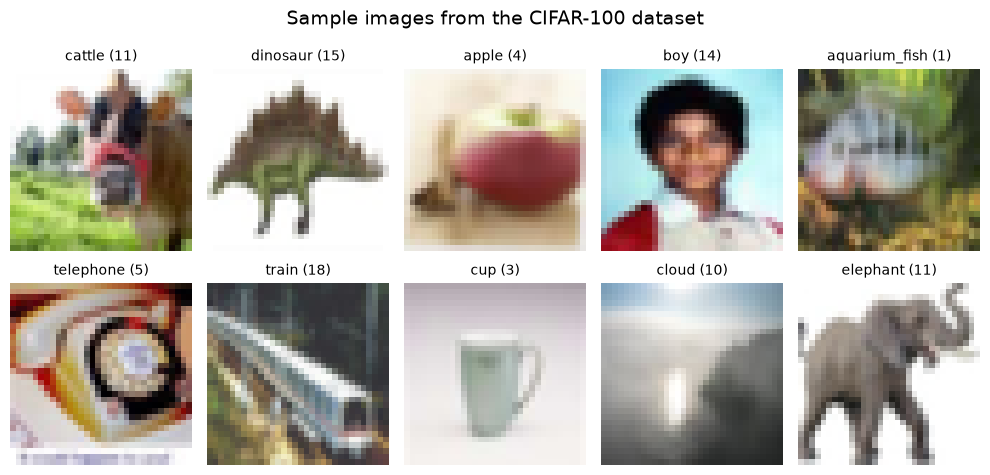

In [8]:
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(10, 5))
# print(f"figures {fig}, axes {axes}")
for idx, ax in enumerate(axes.flat):
    print(f"Plotting image {idx+1} of 10")
    ax.imshow(train_images[idx])
    ax.set_title(f"{fine_names[train_labels[idx]]} ({train_coarse[idx]})", fontsize=10)
    ax.axis("off")


plt.suptitle("Sample images from the CIFAR-100 dataset", fontsize=14)
plt.tight_layout()
plt.show()

Pipeline


In [9]:
scaled = train_images / 255.0  # shape: (50000, 32, 32, 3)
print("Computed mean :", scaled.mean(axis=(0, 1, 2)).round(4))
print("Computed std  :", scaled.std(axis=(0, 1, 2)).round(4))

Computed mean : [0.5071 0.4865 0.4409]
Computed std  : [0.2673 0.2564 0.2762]


In [10]:
# Exact RGB channel mean and std from the DKD / mdistiller CIFAR-100 recipe
CIFAR100_MEAN = np.array([0.5071, 0.4867, 0.4408], dtype=np.float32)
CIFAR100_STD  = np.array([0.2675, 0.2565, 0.2761], dtype=np.float32)


def preprocess_train(img_hwc: np.ndarray) -> np.ndarray:
    """Raw (32, 32, 3) uint8 -> augmented, normalized (3, 32, 32) float32."""
    # print("Raw (32, 32, 3) uint8 -> augmented, normalized (3, 32, 32) float32.")
    # 1. Pad 4 zeros on top/bottom and left/right -> shape becomes (40, 40, 3)
    padded = np.pad(img_hwc, ((4, 4), (4, 4), (0, 0)), mode="constant", constant_values=0)
    # 2. Pick a random 32x32 window (top and left can each be 0..8)
    top = np.random.randint(0, 9)
    left = np.random.randint(0, 9)
    cropped = padded[top : top + 32, left : left + 32]
    # 3. 50% chance left-right mirror flip
    if np.random.rand() < 0.5:
        cropped = cropped[:, ::-1, :]
    
    # 4. Scale to [0, 1], normalize per RGB channel, and transpose HWC -> CHW
    normed = (cropped.astype(np.float32) / 255.0 - CIFAR100_MEAN) / CIFAR100_STD
    return np.ascontiguousarray(normed.transpose(2, 0, 1))

In [11]:
def preprocess_eval(img_hwc: np.ndarray) -> np.ndarray:
    """Raw (32, 32, 3) uint8 -> clean normalized (3, 32, 32) float32 (no crop, no flip)."""
    normed = (img_hwc.astype(np.float32) / 255.0 - CIFAR100_MEAN) / CIFAR100_STD
    return np.ascontiguousarray(normed.transpose(2, 0, 1))

In [12]:

def unnormalize_for_plot(chw: np.ndarray) -> np.ndarray:
    """Undo normalization and CHW -> HWC just so Matplotlib can display a tensor."""
    hwc = chw.transpose(1, 2, 0) * CIFAR100_STD + CIFAR100_MEAN
    return np.clip(hwc, 0.0, 1.0)

In [13]:
# Sanity check on image 0 ('cattle')
sample_eval = preprocess_eval(train_images[0])
print(f"Output shape : {sample_eval.shape}, dtype={sample_eval.dtype}")
print(f"Value range  : min={sample_eval.min():.2f}, max={sample_eval.max():.2f}, mean={sample_eval.mean():.2f}")


Output shape : (3, 32, 32), dtype=float32
Value range  : min=-1.79, max=2.03, mean=0.24


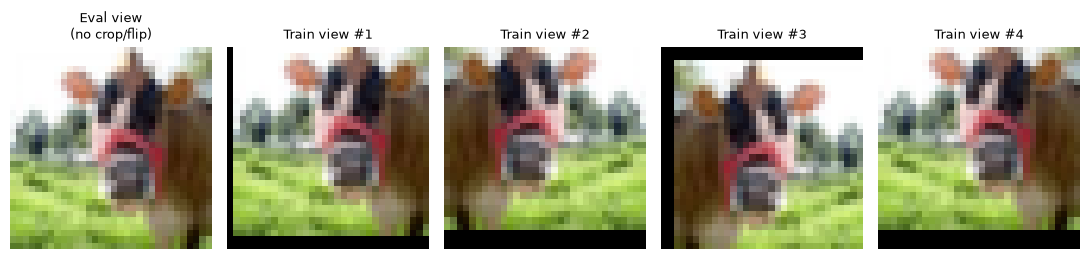

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(11, 2.5))
axes[0].imshow(unnormalize_for_plot(sample_eval))
axes[0].set_title("Eval view\n(no crop/flip)", fontsize=9)
axes[0].axis("off")
for i in range(1, 5):
    aug = preprocess_train(train_images[0])
    axes[i].imshow(unnormalize_for_plot(aug))
    axes[i].set_title(f"Train view #{i}", fontsize=9)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

In [15]:
class SimpleCIFAR100(Dataset):
    def __init__(self, images:np.ndarray, labels: np.ndarray, is_train:bool):
        self.images = images
        self.labels = labels
        self.is_train = is_train

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx: int):
        raw_img = self.images[idx]
        chw = preprocess_train(raw_img) if self.is_train else preprocess_eval(raw_img)
        return torch.from_numpy(chw), int(self.labels[idx])



BATCH_SIZE = 64
train_dataset = SimpleCIFAR100(train_images, train_labels, is_train=True)
test_dataset = SimpleCIFAR100(test_images, test_labels, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

sample_batch_x, sample_batch_y = next(iter(train_loader))
print(f"Train batches per epoch : {len(train_loader)} (50,000 / 64)")
print(f"Test batches            : {len(test_loader)} (10,000 / 128)")
print(f"One batch X shape       : {sample_batch_x.shape}, dtype={sample_batch_x.dtype}")
print(f"One batch Y shape       : {sample_batch_y.shape}, dtype={sample_batch_y.dtype}")

Train batches per epoch : 782 (50,000 / 64)
Test batches            : 157 (10,000 / 128)
One batch X shape       : torch.Size([64, 3, 32, 32]), dtype=torch.float32
One batch Y shape       : torch.Size([64]), dtype=torch.int64


In [16]:
TEACHER_TAR_URL = "https://github.com/megvii-research/mdistiller/releases/download/checkpoints/cifar_teachers.tar"
TEACHER_CKPT_PATH = CKPT_ROOT / "cifar_teachers" / "resnet32x4_vanilla" / "ckpt_epoch_240.pth"


def ensure_teacher_ckpt(ckpt_root: Path = CKPT_ROOT) -> Path:
    ckpt_path = ckpt_root / "cifar_teachers" / "resnet32x4_vanilla" / "ckpt_epoch_240.pth"
    if ckpt_path.exists():
        print(f"Found teacher checkpoint at: {ckpt_path}")
        return ckpt_path
    ckpt_root.mkdir(parents=True, exist_ok=True)
    tar_path = ckpt_root / "cifar_teachers.tar"
    print("Downloading cifar_teachers.tar...")
    try:
        import certifi
        ssl_ctx = ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        ssl_ctx = ssl.create_default_context()
    req = urllib.request.Request(TEACHER_TAR_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, context=ssl_ctx) as resp, tar_path.open("wb") as out:
        while chunk := resp.read(1024 * 1024):
            out.write(chunk)
    with tarfile.open(tar_path, "r") as tar:
        members = [m for m in tar.getmembers() if m.name.startswith("cifar_teachers/resnet32x4_vanilla/")]
        tar.extractall(ckpt_root, members=members)
    tar_path.unlink(missing_ok=True)
    return ckpt_path

In [17]:
ckpt_file = ensure_teacher_ckpt()
print(f"Teacher checkpoint file: {ckpt_file}")


Found teacher checkpoint at: /Users/sufyan.siddiqui/ML-Project/checkpoints/cifar_teachers/resnet32x4_vanilla/ckpt_epoch_240.pth
Teacher checkpoint file: /Users/sufyan.siddiqui/ML-Project/checkpoints/cifar_teachers/resnet32x4_vanilla/ckpt_epoch_240.pth


In [18]:
raw_ckpt = torch.load(ckpt_file, map_location="cpu", weights_only=False)

print("Top-level keys in .pth:", list(raw_ckpt.keys()))
print("First 5 keys:", list(raw_ckpt.keys())[:5])
print("Last 5 keys:", list(raw_ckpt.keys())[-5:])

teacher_state = raw_ckpt["model"]

print("Total tensors in model: ", len(teacher_state))

print("\nFirst 12 Parameter Tensors (name -> shape):")
for name, tensor in list(teacher_state.items())[:12]:
    print(f"{name:>35} : {tensor.shape}")



print("\nLast 4 parameter tensors (name -> shape):")
for name, tensor in list(teacher_state.items())[-4:]:
    print(f"  {name:35s} -> {tuple(tensor.shape)}")










Top-level keys in .pth: ['epoch', 'model', 'accuracy', 'optimizer']
First 5 keys: ['epoch', 'model', 'accuracy', 'optimizer']
Last 5 keys: ['epoch', 'model', 'accuracy', 'optimizer']
Total tensors in model:  172

First 12 Parameter Tensors (name -> shape):
                       conv1.weight : torch.Size([32, 3, 3, 3])
                         bn1.weight : torch.Size([32])
                           bn1.bias : torch.Size([32])
                   bn1.running_mean : torch.Size([32])
                    bn1.running_var : torch.Size([32])
              layer1.0.conv1.weight : torch.Size([64, 32, 3, 3])
                layer1.0.bn1.weight : torch.Size([64])
                  layer1.0.bn1.bias : torch.Size([64])
          layer1.0.bn1.running_mean : torch.Size([64])
           layer1.0.bn1.running_var : torch.Size([64])
              layer1.0.conv2.weight : torch.Size([64, 64, 3, 3])
                layer1.0.bn2.weight : torch.Size([64])

Last 4 parameter tensors (name -> shape):
  layer3.4.

In [19]:
class BasicBlock(nn.Module):
     """Two 3x3 conv layers + skip connection: out = ReLU(F(x) + shortcut(x))."""

     def __init__(
        self,
        in_channels: int,
        out_channels: int,
        stride: int = 1,
        downsample: nn.Module | None = None,
     ):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_channels)
        self.relu  = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_channels)
        self.downsample = downsample

     def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            residual = self.downsample(residual)

        out = out +residual
        out = self.relu(out) # ReLU after residual addition
        return out

# Sanity check 1: Identity shortcut (64 -> 64 channels, 32x32 -> 32x32)

x_same = torch.randn(2, 64, 32, 32)
block_identity = BasicBlock(in_channels=64, out_channels=64, stride=1)
print(f"Output shape of identity block: {block_identity(x_same).shape}")


# Sanity check 2: Downsample shortcut (64 -> 128 channels, 32x32 -> 16x16 via stride=2)
proj = nn.Sequential(
    nn.Conv2d(64, 128, kernel_size=1, stride=2, bias=False),
    nn.BatchNorm2d(128)
)
block_downsample = BasicBlock(in_channels=64, out_channels=128, stride=2, downsample=proj)
print(f"Output shape of downsample block: {block_downsample(x_same).shape}")




Output shape of identity block: torch.Size([2, 64, 32, 32])
Output shape of downsample block: torch.Size([2, 128, 16, 16])


In [21]:
def make_shortcut(in_ch: int, out_ch: int, stride: int) -> nn.Sequential:
    """1x1 conv + BN used whenever a block changes channels or spatial size."""
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
        nn.BatchNorm2d(out_ch),
    )


class StudentResNet8x4(nn.Module):
    def __init__(self, num_classes: int=100):

        super().__init__()

        #1 Entry stem: (B, 3, 32, 32) -> (B, 32, 32, 32)

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(32)
        self.relu  = nn.ReLU(inplace=True)

        #2. 3 Stages, just 1 BasicBlock in each stage!!

        self.layer1 = nn.Sequential(
    
            BasicBlock(in_channels=32, out_channels=64, stride=1, downsample=make_shortcut(32, 64, stride=1)),
        )

        self.layer2 = nn.Sequential(
            BasicBlock(64, 128, stride=2, downsample=make_shortcut(64, 128, stride=2))
        )
        self.layer3 = nn.Sequential(
            BasicBlock(128, 256, stride=2, downsample=make_shortcut(128, 256, stride=2))
        )

        # 3. Classifier head: (B, 256, 8, 8) -> (B, 256, 1, 1) -> (B, 100)

        self.avgpool = nn.AvgPool2d(kernel_size=8)
        self.fc      = nn.Linear(256, num_classes)


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.relu(self.bn1(self.conv1(x)))  # (B, 32, 32, 32)
        x = self.layer1(x)                      # (B, 64, 32, 32)
        x = self.layer2(x)                      # (B, 128, 16, 16)
        x = self.layer3(x)                      # (B, 256, 8, 8)
        x = self.avgpool(x)                     # (B, 256, 1, 1)
        x = torch.flatten(x, start_dim=1)       # (B, 256)
        return self.fc(x)                       # (B, 100)


student_test = StudentResNet8x4()
print(f"Student model architecture: {student_test}")


print("Student output shape :", student_test(torch.randn(4, 3, 32, 32)).shape)
print("Student parameters   :", f"{sum(p.numel() for p in student_test.parameters()):,}")

Student model architecture: StudentResNet8x4(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (downsample): Sequential(
        (0): Conv2d(32, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
  )
  (layer2): Sequential(
    (0): Bas

In [22]:

class TeacherResNet32x4(nn.Module):
    def __init__(self, num_classes: int = 100):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(32)
        self.relu  = nn.ReLU(inplace=True)

        # Each stage has 1 transition block + 4 identity blocks = 5 blocks per stage
        self.layer1 = nn.Sequential(
            BasicBlock(32, 64, stride=1, downsample=make_shortcut(32, 64, stride=1)),
            *[BasicBlock(64, 64) for _ in range(4)],
        )
        self.layer2 = nn.Sequential(
            BasicBlock(64, 128, stride=2, downsample=make_shortcut(64, 128, stride=2)),
            *[BasicBlock(128, 128) for _ in range(4)],
        )
        self.layer3 = nn.Sequential(
            BasicBlock(128, 256, stride=2, downsample=make_shortcut(128, 256, stride=2)),
            *[BasicBlock(256, 256) for _ in range(4)],
        )

        self.avgpool = nn.AvgPool2d(kernel_size=8)
        self.fc      = nn.Linear(256, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.avgpool(x)
        x = torch.flatten(x, start_dim=1)
        return self.fc(x)


# Instantiate Teacher, load Megvii's 172 tensors with strict=True, and freeze it!
teacher = TeacherResNet32x4().to(DEVICE)
load_result = teacher.load_state_dict(teacher_state, strict=True)
teacher.eval()
for p in teacher.parameters():
    p.requires_grad_(False)

t_params = sum(p.numel() for p in teacher.parameters())
s_params = sum(p.numel() for p in student_test.parameters())
print("load_state_dict result :", load_result)
print(f"Teacher parameters     : {t_params:,} ({t_params / s_params:.2f}x larger than Student)")

load_state_dict result : <All keys matched successfully>
Teacher parameters     : 7,433,860 (6.03x larger than Student)


In [23]:
@torch.no_grad()
def evaluate_model(model: nn.Module, loader: DataLoader) -> tuple[float, float]:
    """Returns (average_ce_loss, top1_accuracy_percent) on the given DataLoader."""
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        logits = model(images)
        loss = F.cross_entropy(logits, labels)

        preds = logits.argmax(dim=1)
        bs = labels.size(0)
        total_loss += loss.item() * bs
        total_correct += (preds == labels).sum().item()
        total_samples += bs

    return total_loss / total_samples, 100.0 * total_correct / total_samples


teacher_loss, teacher_acc = evaluate_model(teacher, test_loader)
print(f"Teacher Test Loss     : {teacher_loss:.4f}")
print(f"Teacher Test Accuracy : {teacher_acc:.2f}% (DKD paper reports 79.42%)")

Teacher Test Loss     : 0.8833
Teacher Test Accuracy : 79.42% (DKD paper reports 79.42%)


Evaluate Teacher & Plot Its 2D Feature Space + Decision Boundary

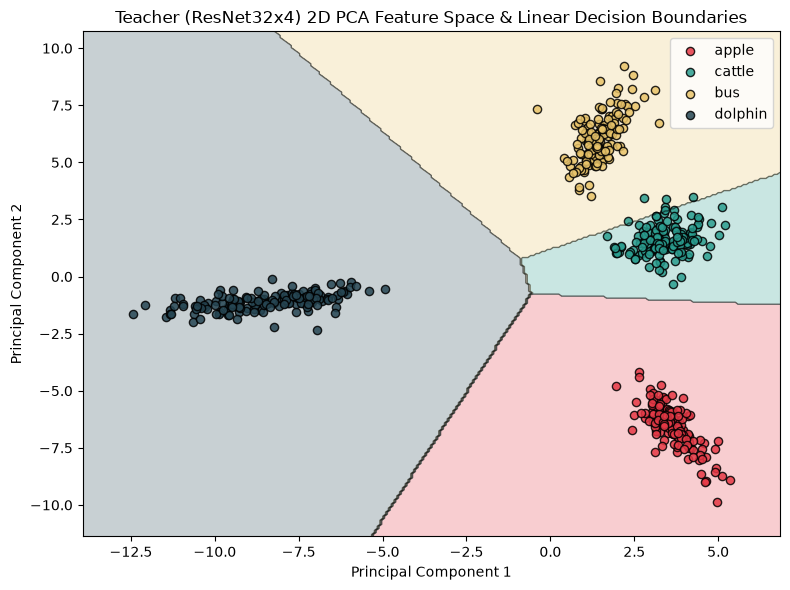

In [ ]:
# Pick 4 clear classes from our training set (150 images per class = 600 points)
chosen_names = ["apple", "cattle", "bus", "dolphin"]
chosen_ids = [fine_names.index(name) for name in chosen_names]

print(f"Chosen classes: {chosen_names}")

sub_imgs, sub_labels = [], []
for cid in chosen_ids:
    idxs = np.where(train_labels == cid)[0][:150]  #what is that? could we use all images of a class? 
    for i in idxs:
        sub_imgs.append(preprocess_eval(train_images[i]))
        sub_labels.append(cid)

x_sub = torch.tensor(np.array(sub_imgs), device=DEVICE)
y_sub = np.array(sub_labels)

# 1. Extract the Teacher's 256-dim penultimate features (right before teacher.fc)
with torch.no_grad():
    h = teacher.relu(teacher.bn1(teacher.conv1(x_sub)))
    h = teacher.layer3(teacher.layer2(teacher.layer1(h)))
    feats_256 = torch.flatten(teacher.avgpool(h), 1).cpu()  # shape: (600, 256)
    #what the heck happened here? 

# 2. Project 256-D -> 2-D via PCA (using SVD on centered features)
mean_256 = feats_256.mean(dim=0, keepdim=True)
centered = feats_256 - mean_256
_, _, Vt = torch.linalg.svd(centered, full_matrices=False)
W_pca = Vt[:2].T                      # (256, 2) top-2 principal directions
pts_2d = (centered @ W_pca).numpy()   # (600, 2) coordinates in 2D!

# 3. Build a 2D grid, map each (u, v) back to 256-D, and ask teacher.fc to classify it!
pad = 1.5
u_grid = np.linspace(pts_2d[:, 0].min() - pad, pts_2d[:, 0].max() + pad, 250)
v_grid = np.linspace(pts_2d[:, 1].min() - pad, pts_2d[:, 1].max() + pad, 250)
UU, VV = np.meshgrid(u_grid, v_grid)
grid_2d = torch.tensor(np.c_[UU.ravel(), VV.ravel()], dtype=torch.float32)

grid_256 = (grid_2d @ W_pca.T + mean_256).to(DEVICE)
with torch.no_grad():
    # Restrict decision regions to our 4 chosen classes
    logits_4 = teacher.fc(grid_256)[:, chosen_ids].cpu().numpy()
region_idx = logits_4.argmax(axis=1).reshape(UU.shape)

# 4. Plot decision regions + real training samples
colors = ["#e63946", "#2a9d8f", "#e9c46a", "#264653"]
plt.figure(figsize=(8, 6))
plt.contourf(UU, VV, region_idx, levels=[-0.5, 0.5, 1.5, 2.5, 3.5], colors=colors, alpha=0.25)
plt.contour(UU, VV, region_idx, levels=[0.5, 1.5, 2.5], colors="k", linewidths=1.0, alpha=0.5)

for k, (cid, cname) in enumerate(zip(chosen_ids, chosen_names)):
    mask = y_sub == cid
    plt.scatter(pts_2d[mask, 0], pts_2d[mask, 1], c=colors[k], label=cname, edgecolors="k", s=35, alpha=0.85)

plt.title("Teacher (ResNet32x4) 2D PCA Feature Space & Linear Decision Boundaries")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()
plt.show()

## Stage 4: Classical Knowledge Distillation (`kd_loss`) & What Temperature $T = 4.0$ Does

Suppose we pass one batch of 64 images into both networks:
- `logits_t = teacher(images)` $\rightarrow$ shape `(64, 100)` raw scores
- `logits_s = student(images)` $\rightarrow$ shape `(64, 100)` raw scores

If we take normal softmax ($T = 1.0$) on a confident Teacher (`logits_t`), the Teacher puts `0.999` on `cattle` and `0.00001` on `elephant` — so all the rich inter-class similarity (**"dark knowledge"**) gets squashed near zero.

**Hinton's 2015 fix:** divide logits by Temperature $T = 4.0$ before softmax:

$$p_i = \frac{\exp(z_i / T)}{\sum_{j=1}^{100} \exp(z_j / T)}$$

Dividing by $4$ softens the peaks (`0.999` becomes say `0.55`, `elephant` becomes `0.08`, while unrelated `apple` stays `0.0001`), exposing how visually similar the Teacher thinks the non-target classes are!

Classical KD then measures **KL Divergence** between the Teacher's soft probabilities $p^T$ and the Student's soft probabilities $p^S$, scaled by $T^2$ (multiplying by $T^2 = 16$ compensates for dividing logits by $T$ twice in the backpropagation gradient chain rule):

$$\mathcal{L}_{\text{KD}} = T^2 \cdot \text{KL}(p^T \parallel p^S)$$

In [28]:
def kd_loss(logits_s: torch.Tensor, logits_t: torch.Tensor, T: float = 4.0) -> torch.Tensor:
    """Classical Hinton KD loss: KL(p_teacher || p_student) * T^2."""
    log_p_s = F.log_softmax(logits_s / T, dim=1)
    p_t     = F.softmax(logits_t / T, dim=1)
    return F.kl_div(log_p_s, p_t, reduction="batchmean") * (T * T)

In [29]:
# Visual check: pass 1 real test image through Teacher and compare T=1.0 vs T=4.0!
one_img, one_label = test_dataset[0]
with torch.no_grad():
    one_logits_t = teacher(one_img.unsqueeze(0).to(DEVICE)).cpu()[0]  # (100,)


p_sharp = F.softmax(one_logits_t / 1.0, dim=0).numpy()
p_soft  = F.softmax(one_logits_t / 4.0, dim=0).numpy()


top5_ids = p_soft.argsort()[::-1][:5]
top5_names = [fine_names[i] for i in top5_ids]

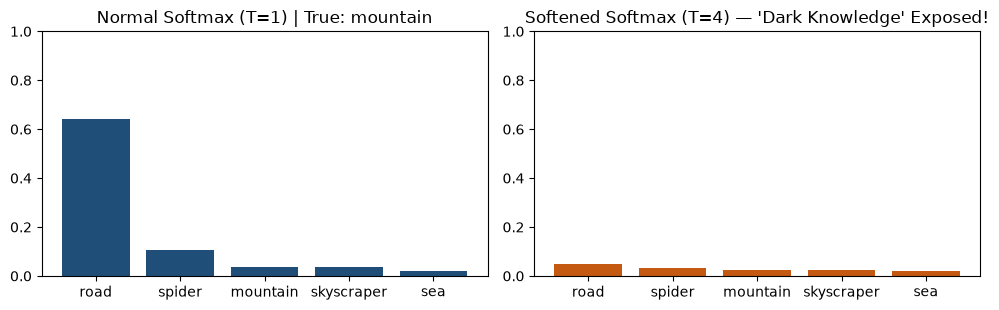

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].bar(top5_names, p_sharp[top5_ids], color="#1f4e79")
axes[0].set_title(f"Normal Softmax (T=1) | True: {fine_names[one_label]}")
axes[0].set_ylim(0, 1.0)
axes[1].bar(top5_names, p_soft[top5_ids], color="#c45911")
axes[1].set_title("Softened Softmax (T=4) — 'Dark Knowledge' Exposed!")
axes[1].set_ylim(0, 1.0)
plt.tight_layout()
plt.show()

In [31]:
student_untrained = StudentResNet8x4().to(DEVICE)

batch_x = sample_batch_x.to(DEVICE)
batch_y = sample_batch_y.to(DEVICE)

with torch.no_grad():
    batch_logits_t = teacher(batch_x)            # (64, 100) trained Teacher scores
batch_logits_s = student_untrained(batch_x)      # (64, 100) fresh untrained Student scores

val_ce = F.cross_entropy(batch_logits_s, batch_y)
val_kd = kd_loss(batch_logits_s, batch_logits_t, T=4.0)

print(f"Untrained Student CE loss : {val_ce.item():.4f} (random guessing over 100 classes is ln(100) = {math.log(100):.4f})")
print(f"Classical KD loss (T=4)   : {val_kd.item():.4f}")

Untrained Student CE loss : 4.6145 (random guessing over 100 classes is ln(100) = 4.6052)
Classical KD loss (T=4)   : 10.6828


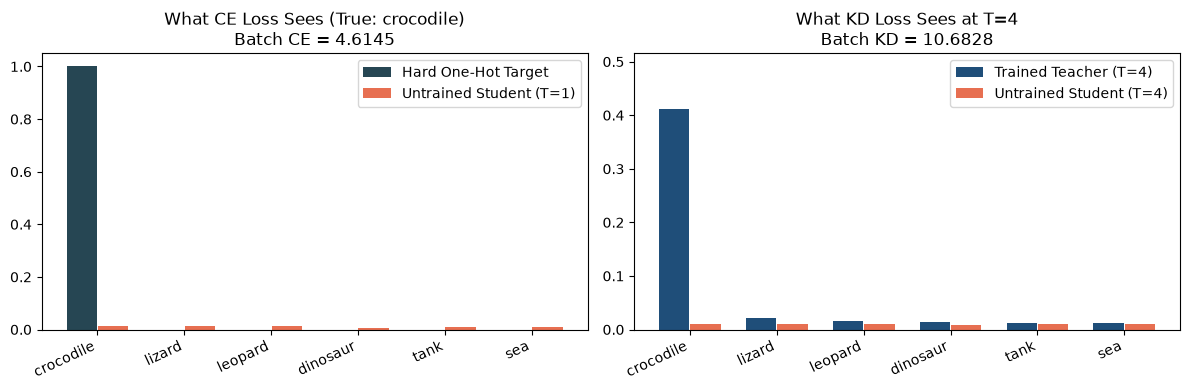

In [32]:
idx_show = 0
true_id = int(batch_y[idx_show].item())

# 1. What Cross-Entropy (CE) compares at T=1: One-hot hard label vs. Student softmax
onehot_target = np.zeros(100)
onehot_target[true_id] = 1.0
p_s_ce = F.softmax(batch_logits_s[idx_show], dim=0).detach().cpu().numpy()

# 2. What Classical KD compares at T=4: Teacher soft probs vs. Student soft probs
p_t_kd = F.softmax(batch_logits_t[idx_show] / 4.0, dim=0).detach().cpu().numpy()
p_s_kd = F.softmax(batch_logits_s[idx_show] / 4.0, dim=0).detach().cpu().numpy()

# Focus on the top-6 classes according to the Teacher so labels are readable
top6 = p_t_kd.argsort()[::-1][:6]
names6 = [fine_names[i] for i in top6]
x_pos = np.arange(len(top6))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: Hard-Label Cross-Entropy view
axes[0].bar(x_pos - 0.18, onehot_target[top6], width=0.35, label="Hard One-Hot Target", color="#264653")
axes[0].bar(x_pos + 0.18, p_s_ce[top6], width=0.35, label="Untrained Student (T=1)", color="#e76f51")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(names6, rotation=25, ha="right")
axes[0].set_ylim(0, 1.05)
axes[0].set_title(f"What CE Loss Sees (True: {fine_names[true_id]})\nBatch CE = {val_ce.item():.4f}")
axes[0].legend()

# Right: Soft-Label KD view (T=4)
axes[1].bar(x_pos - 0.18, p_t_kd[top6], width=0.35, label="Trained Teacher (T=4)", color="#1f4e79")
axes[1].bar(x_pos + 0.18, p_s_kd[top6], width=0.35, label="Untrained Student (T=4)", color="#e76f51")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(names6, rotation=25, ha="right")
axes[1].set_ylim(0, max(p_t_kd[top6].max() * 1.25, 0.25))
axes[1].set_title(f"What KD Loss Sees at T=4\nBatch KD = {val_kd.item():.4f}")
axes[1].legend()

plt.tight_layout()
plt.show()

## Decoupling Classical KD into `TCKD` and `NCKD` (Zhao et al., CVPR 2022)

For an image of true class $t \in \{0, \dots, 99\}$, a 100-class probability vector $p$ contains two distinct decisions:
1. **Binary Target vs. Rest (`TCKD`):** $b = [p_t, \; 1 - p_t]$ — *"How confident is the model on the true class vs. everything else combined?"*
2. **Non-Target Distribution (`NCKD`):** $\hat{p}_i = \frac{\exp(z_i / T)}{\sum_{j \neq t} \exp(z_j / T)}$ for $i \neq t$ — *"Among the 99 wrong classes, which ones look most similar to the image?"* (This is where **dark knowledge** lives!)

Zhao et al. prove algebraically (with **zero approximation**) that Classical KD is secretly:

$$\mathcal{L}_{\text{KD}} = T^2 \cdot \Big( \underbrace{\text{KL}(b^T \parallel b^S)}_{\text{TCKD}} \;+\; \underbrace{(1 - p_t^T)}_{\text{suppression!}} \cdot \underbrace{\text{KL}(\hat{p}^T \parallel \hat{p}^S)}_{\text{NCKD}} \Big)$$

**The flaw:** Whenever the Teacher is confident ($p_t^T \to 1$), the multiplier $(1 - p_t^T) \to 0$ crushes `NCKD`!
**The DKD fix:** Replace $(1 - p_t^T)$ with independent constants $\alpha = 1.0, \beta = 8.0$:

$$\mathcal{L}_{\text{DKD}} = T^2 \cdot (\alpha \cdot \text{TCKD} + \beta \cdot \text{NCKD})$$

In [34]:
def tckd_per_sample(logits_s: torch.Tensor, logits_t: torch.Tensor, targets: torch.Tensor, T: float = 4.0) -> torch.Tensor:
    """Per-sample KL(b^T || b^S) on the 2-class [p_t, 1 - p_t] distribution. Shape: (B,)."""
    idx = targets.view(-1, 1)  # (B, 1)
    p_s = F.softmax(logits_s / T, dim=1)
    p_t = F.softmax(logits_t / T, dim=1)
    pt_s = p_s.gather(1, idx)  # (B, 1) probability on true class
    pt_t = p_t.gather(1, idx)
    b_s = torch.cat([pt_s, 1.0 - pt_s], dim=1).clamp(min=1e-12)  # (B, 2)
    b_t = torch.cat([pt_t, 1.0 - pt_t], dim=1).clamp(min=1e-12)
    return F.kl_div(b_s.log(), b_t, reduction="none").sum(dim=1)

In [35]:
def nckd_per_sample(logits_s: torch.Tensor, logits_t: torch.Tensor, targets: torch.Tensor, T: float = 4.0) -> torch.Tensor:
    """Per-sample KL(p_hat^T || p_hat^S) over the 99 non-target classes. Shape: (B,)."""
    gt_mask = torch.zeros_like(logits_s, dtype=torch.bool).scatter_(1, targets.view(-1, 1), True)
    # Mask out true class ('crocodile') by setting its logit to -1000 -> exp(-1000) == 0!
    masked_s = (logits_s / T).masked_fill(gt_mask, -1000.0)
    masked_t = (logits_t / T).masked_fill(gt_mask, -1000.0)
    return F.kl_div(F.log_softmax(masked_s, dim=1), F.softmax(masked_t, dim=1), reduction="none").sum(dim=1)


In [36]:

def dkd_loss(logits_s: torch.Tensor, logits_t: torch.Tensor, targets: torch.Tensor, alpha: float = 1.0, beta: float = 8.0, T: float = 4.0) -> torch.Tensor:
    """Decoupled Knowledge Distillation loss: (alpha * TCKD + beta * NCKD) * T^2."""
    tckd = tckd_per_sample(logits_s, logits_t, targets, T).mean()
    nckd = nckd_per_sample(logits_s, logits_t, targets, T).mean()
    return (alpha * tckd + beta * nckd) * (T * T)


In [37]:
# === PROOF OF EQUATION (1) ON OUR REAL 64-IMAGE BATCH ===
tckd_i = tckd_per_sample(batch_logits_s, batch_logits_t, batch_y, T=4.0)
nckd_i = nckd_per_sample(batch_logits_s, batch_logits_t, batch_y, T=4.0)
p_t_full = F.softmax(batch_logits_t / 4.0, dim=1)
pt_teacher = p_t_full.gather(1, batch_y.view(-1, 1)).squeeze(1)
reconstructed_kd = (tckd_i + (1.0 - pt_teacher) * nckd_i).mean() * (4.0 ** 2)
val_dkd = dkd_loss(batch_logits_s, batch_logits_t, batch_y, alpha=1.0, beta=8.0, T=4.0)
print(f"Original kd_loss         : {val_kd.item():.6f}")
print(f"TCKD + (1 - p_t^T)*NCKD  : {reconstructed_kd.item():.6f}  <-- EXACT MATCH!")
print(f"Mean (1 - p_t^T) weight  : {(1.0 - pt_teacher).mean().item():.3f} (vs DKD's beta = 8.0!)")
print(f"Decoupled DKD loss       : {val_dkd.item():.4f}")


Original kd_loss         : 10.682806
TCKD + (1 - p_t^T)*NCKD  : 10.682806  <-- EXACT MATCH!
Mean (1 - p_t^T) weight  : 0.761 (vs DKD's beta = 8.0!)
Decoupled DKD loss       : 24.2934


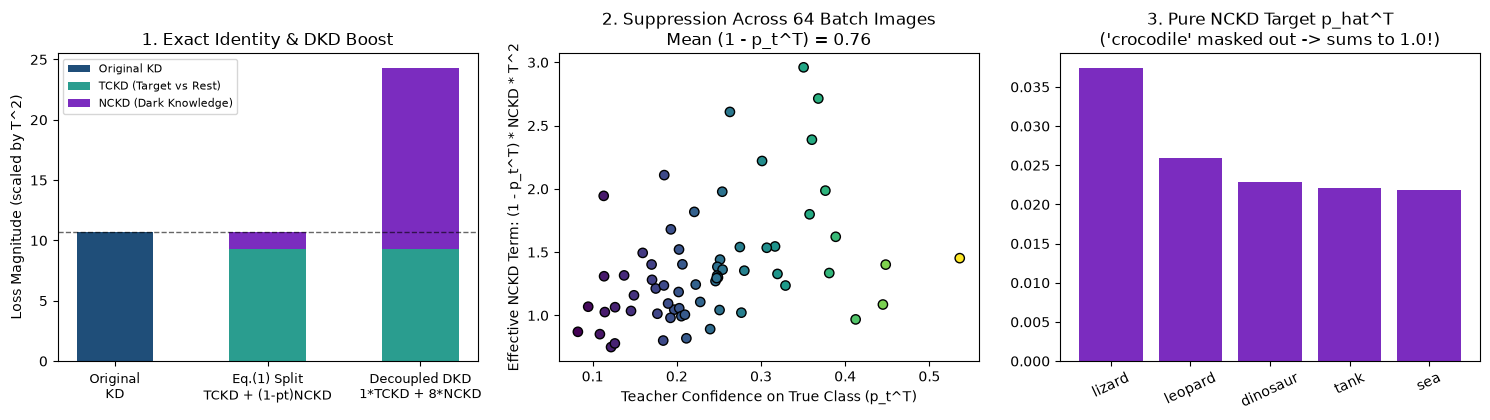

In [38]:
T_val = 4.0
tckd_scaled = (tckd_i.mean() * T_val**2).item()
coupled_nckd_scaled = (((1.0 - pt_teacher) * nckd_i).mean() * T_val**2).item()
dkd_nckd_scaled = (8.0 * nckd_i.mean() * T_val**2).item()

pt_np = pt_teacher.detach().cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

# Panel 1: Stacked Bar Comparison (KD == Coupled Split vs DKD)
labels_bar = ["Original\nKD", "Eq.(1) Split\nTCKD + (1-pt)NCKD", "Decoupled DKD\n1*TCKD + 8*NCKD"]
# Bar 1: solid KD; Bar 2 & 3: green TCKD bottom + purple NCKD top
axes[0].bar([0], [val_kd.item()], color="#1f4e79", width=0.5, label="Original KD")
axes[0].bar([1, 2], [tckd_scaled, tckd_scaled], color="#2a9d8f", width=0.5, label="TCKD (Target vs Rest)")
axes[0].bar([1, 2], [coupled_nckd_scaled, dkd_nckd_scaled], bottom=[tckd_scaled, tckd_scaled], color="#7b2cbf", width=0.5, label="NCKD (Dark Knowledge)")
axes[0].axhline(val_kd.item(), color="k", linestyle="--", linewidth=1, alpha=0.6)
axes[0].set_xticks([0, 1, 2])
axes[0].set_xticklabels(labels_bar, fontsize=9)
axes[0].set_ylabel("Loss Magnitude (scaled by T^2)")
axes[0].set_title("1. Exact Identity & DKD Boost")
axes[0].legend(fontsize=8)

# Panel 2: How Classical KD Suppresses NCKD on Confident Images (64 batch samples)
effective_nckd_i = ((1.0 - pt_teacher) * nckd_i * T_val**2).detach().cpu().numpy()
axes[1].scatter(pt_np, effective_nckd_i, c=pt_np, cmap="viridis", edgecolors="k", s=45)
axes[1].set_xlabel("Teacher Confidence on True Class (p_t^T)")
axes[1].set_ylabel("Effective NCKD Term: (1 - p_t^T) * NCKD * T^2")
axes[1].set_title(f"2. Suppression Across 64 Batch Images\nMean (1 - p_t^T) = {(1 - pt_np).mean():.2f}")

# Panel 3: Image 0 ('crocodile') Non-Target Conditional p_hat^T (True Class Masked Out!)
gt_mask_0 = torch.zeros(100, dtype=torch.bool, device=DEVICE)
gt_mask_0[batch_y[0]] = True
p_hat_t0 = F.softmax((batch_logits_t[0] / T_val).masked_fill(gt_mask_0, -1000.0), dim=0).cpu().numpy()
top5_nontarget = p_hat_t0.argsort()[::-1][:5]

axes[2].bar([fine_names[i] for i in top5_nontarget], p_hat_t0[top5_nontarget], color="#7b2cbf")
axes[2].set_title(f"3. Pure NCKD Target p_hat^T\n('{fine_names[int(batch_y[0])]}' masked out -> sums to 1.0!)")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()